# Análise Exploratória de Dados Multivariada - Dados de Gênero

O código apresentado neste notebook realiza uma análise exploratória entre as variáveis presentes na base de dados e tem como objetivo identificar padrões e verificar a viabilidade da base de dados para o contexto de justiça algorítimica. 

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import stats

import statsmodels.formula.api as smf

In [2]:
df = pd.read_csv("../dataset/dataset_limpo_multivariado.csv")

Há alguns dados sensíveis principais que podem ser usados para uma investigação de justiça algorítmica. Na nossa base de dados eles são: 

- Idade
- Grau de instrução escolar
- Status civil
- Status econômico (tendo como proxy residência)
- Sexo biológico 

Abaixo vou focar em realizar uma exploração estatística entre as features/variaveis com relação ao gênero dos clientes, o objetivo de verificar se possuímos correlações suficientes que justifiquem um aprofundamento em situações de (in)justiça algorítimica. As variáveis que serão correlacionadas são:

- Tipo de proposta aprovada
- Valor proposto no contrato
- Valor aprovado no contrato
- Tempo máximo de atraso de uma parcela
- Tempo total de atraso contando todas as parcelas
- Valor das prestações
- Valor de juros aprovado
- Taxa de juros aprovado
- Histórico no SPC, SERASA e BNB

Não são as variáveis mais importantes, mas pode ter alguma utilidade investigar as variáveis de:

- Valor do seguro

Para facilitar as analises, vou criar uma coluna que indica a porcentagem de mulheres dentro daquele grupo de clientes

In [3]:
df['PORCENTAGEM_MULHERES_GRUPO'] = (df['QT_CLI_MLH']/df['QT_CLI']).round(1)

E também vou criar uma coluna categória que indique se aquele contrato diz respeito a um conjunto de clientes composto exclusivamente por mulheres, exclusivamente por homens ou se é misto.

In [4]:
condicoes = [df['PORCENTAGEM_MULHERES_GRUPO'] == 0,
    (df['PORCENTAGEM_MULHERES_GRUPO'] > 0) & (df['PORCENTAGEM_MULHERES_GRUPO'] < 1),
    df['PORCENTAGEM_MULHERES_GRUPO'] == 1,
]
nomes = ['Apenas Homens', 'Misto', 'Apenas Mulheres']

df['PERFIL_GENERO_GRUPO_CLIENTES'] = np.select(condicoes, nomes, default='Indefinido')

Acredito que possa ser mais interessante realizar uma separação do meu dataset em três grandes grupos demográficos: (1) o grupo em que devedor seja composto apenas por grupo de mulheres, (2) o grupo devedor seja composto apenas por grupo de homens e (3) o grupo devedor é um grupo misto em gênero.

In [5]:
df_apenas_mulheres = df[df['PERFIL_GENERO_GRUPO_CLIENTES'] == 'Apenas Mulheres']
df_apenas_homens = df[df['PERFIL_GENERO_GRUPO_CLIENTES'] == 'Apenas Homens']
df_misto = df[df['PERFIL_GENERO_GRUPO_CLIENTES'] == 'Misto']

In [6]:
print(f'Há {len(df_apenas_mulheres)} linhas/registros de grupo de clientes composto apenas por mulheres')
print(f'Há {len(df_apenas_homens)} linhas/registros de grupos de clientes composto apenas por homens')
print(f'Há {len(df_misto)} linhas/registros de grupo misto em gênero composto')

Há 83025 linhas/registros de grupo de clientes composto apenas por mulheres
Há 19909 linhas/registros de grupos de clientes composto apenas por homens
Há 176797 linhas/registros de grupo misto em gênero composto


Observamos que em maioria os grupos de pessoas devedoras é heterogêneo (176.797 grupos), seguido por grupos exclusivo de mulheres (83.025 grupos). É evidente portanto que há um desbalancemanto na base de dados, vou investigar melhor como as demais variáveis estão distribuidas considerando essa separação inicial dos grupos.

In [7]:
media_mulheres = df_apenas_mulheres['QT_CLI'].mean()
media_homens = df_apenas_homens['QT_CLI'].mean()
media_misto = df_misto['QT_CLI'].mean()

mediana_mulheres = df_apenas_mulheres['QT_CLI'].median()
mediana_homens = df_apenas_homens['QT_CLI'].median()
mediana_misto = df_misto['QT_CLI'].median()

print(f'Há em média {media_mulheres:.2f} mulheres por contrato, no grupo de clientes exclusivo de mulheres')
print(f'Há em média {media_homens:.2f} homens por contrato, no grupo de clientes exclusivo de homens')
print(f'Há em média {media_misto:.2f} pessoas por contrato, no grupo de clientes misto em gênero')
print("\n")
print(f'A mediana é de {mediana_mulheres:.2f} mulheres por contrato, no grupo de clientes exclusivo de mulheres')
print(f'A mediana é de {mediana_homens:.2f} homens por contrato, no grupo de clientes exclusivo de homens')
print(f'A mediana é de {mediana_misto:.2f} pessoas por contrato, no grupo de clientes misto em gênero')

Há em média 3.88 mulheres por contrato, no grupo de clientes exclusivo de mulheres
Há em média 3.54 homens por contrato, no grupo de clientes exclusivo de homens
Há em média 4.23 pessoas por contrato, no grupo de clientes misto em gênero


A mediana é de 4.00 mulheres por contrato, no grupo de clientes exclusivo de mulheres
A mediana é de 3.00 homens por contrato, no grupo de clientes exclusivo de homens
A mediana é de 4.00 pessoas por contrato, no grupo de clientes misto em gênero


Arredondando as casas decimais (afinal não existe meia pessoa), observamos que a mediana da quantidade de pessoas por contrato/empréstimo é menor entre os homens.

Para as realizar as analises abaixo, vou realizar uma análise entreos três grupos para que eu consiga ter um contexto do comportamento do banco e dos clientes. Nos próximos notebooks, vou tentar sempre que conveniente manter separado em (1) análise comparativa e de _fairness_ entre os extremos - grupos de apenas mulheres e grupos de apenas homens, (2) análise interna do grupo misto de clientes. Acho que isso vai me ajudar a evitar que os extremos enviesem análises de correlações entre variáveis. 

#### Análise sobre o tipo de proposta

In [8]:
tabela = pd.crosstab(df['PERFIL_GENERO_GRUPO_CLIENTES'], df['ID_TP_PRP'])
tabela

ID_TP_PRP,0,1,2
PERFIL_GENERO_GRUPO_CLIENTES,,,
Apenas Homens,14671,4849,389
Apenas Mulheres,57457,24359,1209
Misto,129990,44245,2562


In [9]:
tabela_tipo_proposta_por_grupo = (pd.crosstab(df['PERFIL_GENERO_GRUPO_CLIENTES'], df['ID_TP_PRP'], normalize='index')*100).round(2)

display(tabela_tipo_proposta_por_grupo)

ID_TP_PRP,0,1,2
PERFIL_GENERO_GRUPO_CLIENTES,,,
Apenas Homens,73.69,24.36,1.95
Apenas Mulheres,69.20,29.34,1.46
Misto,73.53,25.03,1.45


O grupo exclusivo de mulheres, possui uma quantidade maior de propostas do tipo renegociadas (Tipo 1) do que os demais grupos e uma taxa de propostas normais (Tipo 0) e refinanciadas (Tipo 2) relativamente menor que a dos grupos de clientes exclusivamente masculinos.

De acordo com esse artigo do [Jusbrasil](https://www.jusbrasil.com.br/artigos/renegociacao-ou-refinanciamento-qual-a-melhor-opcao-para-sua-empresa/4730984714), há uma diferença entre renegociação e refinanciamento. 

A renegociação ocorre quando o cliente procura o banco ou instituição financeira com a qual já tem o débito para tentar mudar as condições do contrato. Na prática, é como se sentar à mesa para discutir novas regras para o pagamento, seja estendendo o prazo, reduzindo o valor das parcelas ou renegociando os juros. As vantagens dessa estratégia é que ocorrendo uma negociação bem-sucedida haverá a possibilidade de diminuir o valor das prestações mensais para que caiba no orçamento e a criação de um novo cronograma de pagamento mais adequado à realidade atual da empresa.

Já o refinanciamento significa buscar um novo financiamento para pagar a dívida antiga. Neste caso, a empresa pode procurar o mesmo banco e refinanciar a dívida inicial com um novo contrato ou mesmo buscar perante outra instituição financeira uma linha de crédito para quitar o antigo, possibilitando condições diferentes, como juros mais baixos ou prazos maiores.

Assim, uma possível interpretação que pode ser feita é que grupos exclusivo de mulheres tendem a representar um risco maior, visto que há maior demanda de renegociação de contratos para a resolução de seus débitos, o que pode ser um indicador de maior inadimplência.

#### Análise sobre valores solicitados na proposta

In [10]:
valor_proposto_por_grupo = (df.groupby('PERFIL_GENERO_GRUPO_CLIENTES')['VR_SOL_PRP'].agg(['count', 'mean', 'median', 'std', 'max']).round(2))
valor_proposto_por_grupo

,count,mean,median,std,max
PERFIL_GENERO_GRUPO_CLIENTES,,,,,
Apenas Homens,19909,13007.73,9390.0,10965.32,146790.0
Apenas Mulheres,83025,11322.31,8380.0,10950.78,952346.0
Misto,176797,12906.71,9347.0,11089.81,327460.0


A mediana solicitada pelas mulheres (R$ 8.385,00) é menor do que a dos homens (R$ 9.390,00) e dos clientes mistos em gênero (R$ 9.347,00). A média segue a mesma tendência: mulheres pedem em média R$ 11.322, enquanto homens e mistos pedem mais de R$ 13.007. Vejo que há dois pontos interessantes aqui: 

1. Medidas de posição são maiores para grupos apenas de homens, mesmo que eles estejam em uma quantidade significativamente menor. 
2. Mesmo com homens em média realizando empréstimo de valores maiores, eles possuem maior quantidade de contratos do tipo "Normal" e mulheres possuem mais propostas renegociadas, apesar de solicitarem valores menores, em geral.  

Há um **indicativo** que mesmo solicitando menos, as mulheres possuem maior dificuldade em realizar pagamentos, o que é reforçado pela quantidade de contratos renegociados - ou seja, estão tentando pagar uma crédito de contrato anterior.

In [11]:
df["VR_SOL_PRP_PER_CAPITA"] = df["VR_SOL_PRP"] / df["QT_CLI"]

/tmp/ipykernel_65070/359740942.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["VR_SOL_PRP_PER_CAPITA"] = df["VR_SOL_PRP"] / df["QT_CLI"]


In [12]:
valor_proposto_per_capita_por_grupo = (df.groupby('PERFIL_GENERO_GRUPO_CLIENTES')['VR_SOL_PRP_PER_CAPITA'].agg(['count', 'mean', 'median', 'std', 'max']).round(2))
valor_proposto_per_capita_por_grupo

,count,mean,median,std,max
PERFIL_GENERO_GRUPO_CLIENTES,,,,,
Apenas Homens,19909,3670.61,2760.00,2934.95,31363.33
Apenas Mulheres,83025,2926.20,2218.00,2522.94,190469.20
Misto,176797,3087.84,2287.29,2492.98,81865.00


Ao observar o valor **solicitado** per capita à quantidade de clientes do contrato, tanto a média quanto a mediana do grupo exclusivamente formado por homens possui valor maior do que o grupo exclusivamente de mulheres e o grupo misto. Observo então que o grupo exclusivo de mulheres se demonstra mais conservador nas propostas enviadas, há de se observar se há alguma relação com o natureza empresarial de negócio, mas é fato que as mulheres possuem menor renda em relação aos homens e esse valor per capita pode ser um reflexo disso.

- **HIPOTESE:** Analisar relação com a natureza empresarial do negócio.

#### Análise sobre valores aprovados

In [13]:
df_copy = df.copy()

In [14]:
descr_valor_aprovado_por_grupo = (df_copy.groupby('PERFIL_GENERO_GRUPO_CLIENTES')['VR_APR_PRP'].agg(['count', 'mean', 'median', 'std', 'max']).round(2))
descr_valor_aprovado_por_grupo

,count,mean,median,std,max
PERFIL_GENERO_GRUPO_CLIENTES,,,,,
Apenas Homens,19909,12068.09,8804.0,10243.96,84182.0
Apenas Mulheres,83025,10372.33,7752.0,8780.28,94855.0
Misto,176797,11850.86,8562.0,10179.69,118675.0


In [15]:
df_copy["VR_APR_PER_CAPITA"] = df_copy["VR_APR_PRP"] / df_copy["QT_CLI"]

In [16]:
descr_aprovacao_per_capita = (df_copy.groupby('PERFIL_GENERO_GRUPO_CLIENTES')['VR_APR_PER_CAPITA'].agg(['count', 'mean', 'median', 'std', 'max']).round(2))
descr_aprovacao_per_capita

,count,mean,median,std,max
PERFIL_GENERO_GRUPO_CLIENTES,,,,,
Apenas Homens,19909,3404.78,2582.00,2737.30,14260.0
Apenas Mulheres,83025,2682.83,2099.67,2124.67,14147.0
Misto,176797,2835.55,2100.00,2290.94,15000.0


Grupos exclusivos de mulheres possuem uma mediana inferior a grupos exclusivos de homens e grupos mistos no que diz respeito ao valor aprovado de crédito, o que faz sentido tendo em vista que elas já solicitam valores menores. Em uma análise per capita, vejo que o grupo de homens ainda possui um valor aprovado (tanto em média como em mediana) substancialmente superior ao grupo de mulheres e ao grupo misto em gênero. 

Acredito que o melhor indicativo para alguma hipótese seja analisar uma taxa entre o valor aprovado da proposta em relação à o que foi solicitado

#### Análise da relação entre grupos e a taxa do valor aprovado de proposta em relação ao solicitado

Visto que o valor solicitado é definido pelos clientes e que grupos formados exclusivamente por mulheres e grupos mistos solicitam valores menores que grupos exclusivamente masculinos seja por cautela ou diferença de poder de compra, podemos analisar se há alguma associação entre o gênero dos clientes dos grupo e a taxa de crédito concedido pelo banco após análise. Ou seja, a razão entre o valor aprovado e o solicitado.

In [17]:
# Porcentagem do valor aprovado em relação ao valor solicitado
df_copy['PRT_VLR_APR_SOL'] = (df_copy['VR_APR_PRP']/df_copy['VR_SOL_PRP']) * 100

In [ ]:
resumo_aprovacao = (df_copy.groupby('PERFIL_GENERO_GRUPO_CLIENTES')['PRT_VLR_APR_SOL'].agg(['count', 'mean', 'median', 'std', 'max']).round(2))
resumo_aprovacao

,count,mean,median,std,max
PERFIL_GENERO_GRUPO_CLIENTES,,,,,
Apenas Homens,19909,93.31,100.0,12.47,313.52
Apenas Mulheres,83025,92.36,100.0,12.76,664.38
Misto,176797,92.27,99.6,12.46,314.29


O valor máximo de cada grupo é superior a 1, ou seja, há propostas que o valor aprovado é o dobro e até o triplo do valor solicitado. Preciso investigar se essas propostas possuem alguma característica em comum ou se são ruídos de anotação.

Para simplificação da análise, vou selecionar apenas em que o valor é igual ou menor que 100.

In [ ]:
df_taxa_aprovacao_limitada = df_copy[df_copy['PRT_VLR_APR_SOL'] <= 100]

resumo_aprovacao = (df_taxa_aprovacao_limitada.groupby('PERFIL_GENERO_GRUPO_CLIENTES')['PRT_VLR_APR_SOL'].agg(['count', 'mean', 'median', 'std', 'max']).round(2))
resumo_aprovacao

,count,mean,median,std,max
PERFIL_GENERO_GRUPO_CLIENTES,,,,,
Apenas Homens,19737,93.16,100.00,12.22,100.0
Apenas Mulheres,82206,92.20,100.00,12.46,100.0
Misto,175210,92.13,99.37,12.34,100.0


Com uma limitação para análise de contratos com uma taxa de aprovação de igual ou menor que 100%, a mediana se mantém a mesma (o valor aprovado é exatamente o valor que foi solicitado) porém a média dos grupos composto apenas por mulheres ainda é inferior aos homens. Vou investigar os quartis, para obter maior entendimento da distribuição e posteriormente, caso necessário, investigo se há relação com alguma outra variável categórica.

In [20]:
resumo_aprovacao = (
    df_taxa_aprovacao_limitada
    .groupby('PERFIL_GENERO_GRUPO_CLIENTES')['PRT_VLR_APR_SOL']
    .agg(
        count='count',
        media='mean',
        std='std',
        minimo='min',
        Q1=lambda x: x.quantile(0.25),      # 1º Quartil (25%)
        mediana='median',                   # 2º Quartil (50%)
        Q3=lambda x: x.quantile(0.75),      # 3º Quartil (75%)
        maximo='max'
    )
    .round(2)
)

resumo_aprovacao

,count,media,std,minimo,Q1,mediana,Q3,maximo
PERFIL_GENERO_GRUPO_CLIENTES,,,,,,,,
Apenas Homens,19737,93.16,12.22,12.42,90.55,100.00,100.0,100.0
Apenas Mulheres,82206,92.20,12.46,2.17,88.29,100.00,100.0,100.0
Misto,175210,92.13,12.34,4.35,88.24,99.37,100.0,100.0


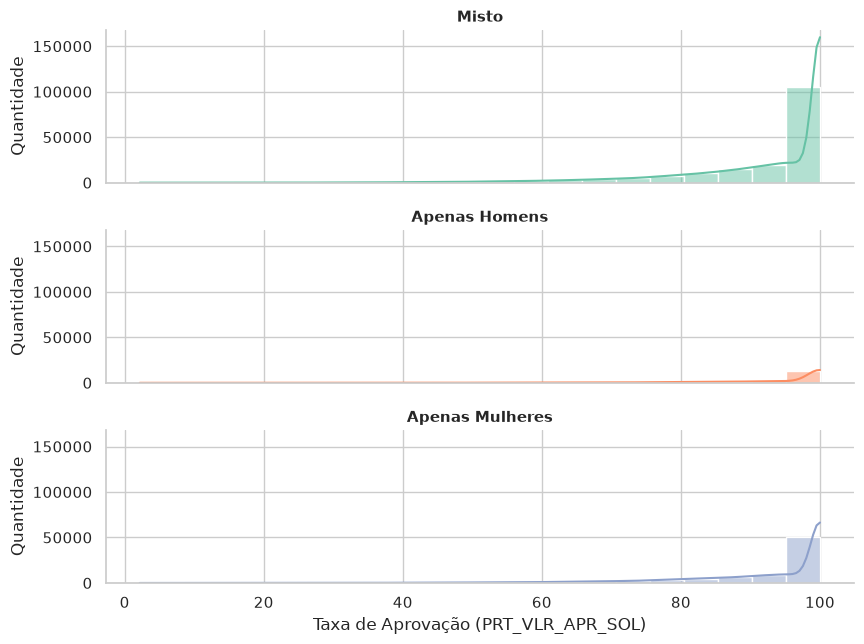

In [25]:
sns.set_theme(style="whitegrid")

g = sns.displot(
    data=df_taxa_aprovacao_limitada,
    x='PRT_VLR_APR_SOL',
    row='PERFIL_GENERO_GRUPO_CLIENTES',  # Empilha um abaixo do outro na horizontal
    hue='PERFIL_GENERO_GRUPO_CLIENTES',
    kind='hist',
    kde=True,          # Adiciona a linha suave por cima das barras (remova se quiser só barras)
    bins=20,           # Quantidade de barras
    height=2.2,
    aspect=4,          # Deixa o gráfico bem largo na horizontal
    legend=False,
    palette='Set2'
)

g.set_titles("{row_name}", size=11, weight='bold')
g.set_axis_labels("Taxa de Aprovação (PRT_VLR_APR_SOL)", "Quantidade")
sns.despine()

plt.tight_layout()
plt.show()

A taxa de aprovação de grupos exclusivamente formado por mulheres é mais distribuida do que grupos formados exclusivamente por homens, mas menos do que o grupo misto. Vejo então que analisando todos os tipos de contratos, devido a possível indicação de que mulheres possuem maior risco devido à sua taxa de contratos renegociados, esse fator faz sentido. Há maior cautela na aprovação de crédito para grupos que possuem mulheres. Devo agora analisar se isto se confirma por meio de variáveis mais características de indicação de risco.

### Dados de Juros

In [26]:
agg_valor_taxa_juros_aprovada = df_copy.groupby('PERFIL_GENERO_GRUPO_CLIENTES')['TX_JRS_APR'].agg(['mean', 'median', 'std', 'min', 'max']).round(2)
agg_valor_taxa_juros_aprovada

,mean,median,std,min,max
PERFIL_GENERO_GRUPO_CLIENTES,,,,,
Apenas Homens,1.97,2.3,0.42,1.06,2.3
Apenas Mulheres,1.94,2.3,0.44,1.06,2.3
Misto,1.98,2.3,0.42,0.95,2.3


Ao se observar a taxa de juros aprovada para cada um dos grupos, vejo que o valor da taxa é praticamente o mesmo para todos. Mesma mediana, mesmo valor máximo e mesmo valor mínimo para grupos exclusivamente masculinos e femininos. Minha interpretação é que apesar dos grupos exclusivamente femininos solicitarem valores proporcionalmente menores, terem relativamente uma aprovação menor ao solicitado, possuirem menor inadimplência e quando estão nessa situação, costumam realizar o pagamento mais rapidamente. 

Com isso, vejo que há diversos indicativos de grupos exclusivamente masculinos possuem um igua em relação à grupos compostos exclusivamente por mulheres e grupos mistos. Digo tratamento igual tendo em vista que possuem as mesmas condições de juros, quantidade de prestações aprovadas, periodicidade semelhante aos demais grupos apesar de possuírem comportamentos de maior risco ao banco. Isso é conhecido como tratamento igual de desiguais. - A análise de risco encontras-se no notebook 05.

Entendo que esses comportamentos ocorreram depois do contrato assinado, mas então posso investigar os dados passados que foram fornecidos pela pesquisa cadastral dos clientes que indicam a quantidade e a média de passagens negativas pelo SPC, Serada e pelo BNB.

In [27]:
agg_valor_taxa_juros_aprovada = df_copy.groupby('ID_TP_PRP')['TX_JRS_APR'].agg(['mean', 'median', 'std', 'min', 'max']).round(2)
agg_valor_taxa_juros_aprovada

,mean,median,std,min,max
ID_TP_PRP,,,,,
0,2.20,2.30,0.18,0.95,2.3
1,1.31,1.37,0.15,1.08,2.0
2,2.00,2.30,0.42,1.06,2.3


### Dados de Seguro

### Dados de Pesquisa Cadastrais

### Dados de Grupos Novos

### Dados de Natureza de Negócio